<div dir="ltr" style="text-align:left; line-height:1.9">
<h2>Introductory Diabetes Classification Using a Correlation-Based Score</h2>
<p>In this exercise, we create a <strong>numerical score</strong> from the recorded features and then use a threshold to predict one of two labels: 0 (non-diabetic) and 1 (diabetic). The coefficient of each feature is calculated from its correlation with the target label in the <strong>training set</strong>. This is a simple educational approach, not a clinical diagnostic method or an optimized classifier.</p><p><strong>Prerequisite:</strong> The file <code>diabetes.csv</code> must be in the notebook's working directory. The last column contains the target label, and the eight columns before it contain the features. Run the cells in order.</p>
</div>

<div dir="ltr" style="text-align:left; line-height:1.9">
<h2>1. Loading the Data and Random Splitting</h2>
<p>We use <code>train_test_split</code> to divide the data into 80% for training and 20% for testing. The <code>stratify</code> option preserves approximately the same proportions of labels 0 and 1 in both subsets. Setting <code>random_state=42</code> makes the random split reproducible. The test data is not used to construct the score or determine the threshold; it is reserved for the final evaluation.</p>
</div>

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, accuracy_score

data = np.loadtxt("diabetes.csv", delimiter=",", skiprows=1)
xTrain, xTest, yTrain, yTest = train_test_split(
    data[:, :-1], data[:, -1], test_size=0.2, stratify=data[:, -1], #random_state=42
)

<div dir="ltr" style="text-align:left; line-height:1.9">
<h2>2. Feature Standardization</h2>
<p>To make feature scales comparable, we use the formula <code>z = (x - mean) / std</code>. The <strong>mean and standard deviation are calculated using only the training data</strong>, and the same values are then applied to the test data. Otherwise, information leakage would occur. If a column has a standard deviation of zero, we set it to 1 to avoid division by zero.</p>
</div>

In [20]:
mean, std = xTrain.mean(axis=0), xTrain.std(axis=0)
std[std == 0] = 1
xTrainNorm = (xTrain - mean) / std
xTestNorm = (xTest - mean) / std

<div dir="ltr" style="text-align:left; line-height:1.9">
<h2>3. Calculating Weights Using Pearson Correlation</h2>
<p>For each feature, we calculate its Pearson correlation with the 0/1 target label using the <strong>training data</strong>. A positive value means that higher values of the feature are generally associated with label 1, while a negative value indicates the opposite direction. <strong>Correlation does not imply causation.</strong> The <code>np.corrcoef</code> function creates the correlation matrix, and <code>[-1, :-1]</code> selects the correlations between all features and the last column (the target label).</p>
</div>

In [21]:
featureNames = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness",
                "Insulin", "BMI", "DiabetesPedigreeFunction", "Age"]
coefficients = np.nan_to_num(np.corrcoef(xTrainNorm.T, yTrain)[-1, :-1])
for name, weight in zip(featureNames, coefficients):
    print(f"{name:25s} {weight:+.3f}")

Pregnancies               +0.223
Glucose                   +0.437
BloodPressure             +0.078
SkinThickness             +0.087
Insulin                   +0.164
BMI                       +0.271
DiabetesPedigreeFunction  +0.156
Age                       +0.241


<div dir="ltr" style="text-align:left; line-height:1.9">
<h2>4. Generating Scores and Comparing the Two Groups</h2>
<p>Each person's score is calculated as <code>score = xNorm @ coefficients</code>. In other words, it is the sum of the standardized feature values multiplied by their correlation weights. This score is <strong>not a probability of having diabetes</strong> and may fall outside the range from 0 to 1. We compare the mean and range of the scores for the two groups using <strong>only the training data</strong>.</p>
</div>

In [22]:
trainScores = xTrainNorm @ coefficients
testScores = xTestNorm @ coefficients
healthyScores = trainScores[yTrain == 0]
diabeticScores = trainScores[yTrain == 1]
for name, scores in [("Healthy", healthyScores), ("Diabetic", diabeticScores)]:
    print(f"{name}: mean={scores.mean():.2f}, range=({scores.min():.2f}, {scores.max():.2f})")

Healthy: mean=-0.32, range=(-2.77, 3.13)
Diabetic: mean=0.60, range=(-1.44, 2.46)


<div dir="ltr" style="text-align:left; line-height:1.9">
<h2>5. Relative Histograms and Threshold Selection</h2>
<p>We plot the two histograms using <strong>shared bin edges</strong> and <code>density=True</code>. In this setting, the area under each histogram is 1, so differences in the sizes of the two groups do not distort the comparison. We define the threshold as the <strong>boundary of the first bin</strong> in which the density of the diabetic group becomes greater than the density of the healthy group, provided that this was not the case in the previous bin.</p><p><strong>Limitation:</strong> This method is sensitive to the number of bins and to sample noise. There may be multiple crossings or no crossing at all. The resulting threshold is not necessarily the best one in terms of accuracy, sensitivity, or specificity.</p>
</div>

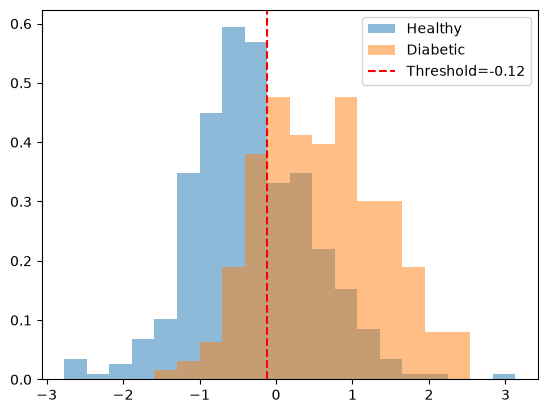

Threshold: -0.11569927290184578


In [23]:
bins = np.histogram_bin_edges(trainScores, bins=20)
h, _ = np.histogram(healthyScores, bins=bins, density=True)
d, _ = np.histogram(diabeticScores, bins=bins, density=True)
idx = np.flatnonzero((d[1:] > h[1:]) & (d[:-1] <= h[:-1]))
threshold = bins[idx[0] + 1] if len(idx) else None

plt.hist(healthyScores, bins=bins, density=True, alpha=0.5, label="Healthy")
plt.hist(diabeticScores, bins=bins, density=True, alpha=0.5, label="Diabetic")
if threshold is not None:
    plt.axvline(threshold, color="red", ls="--", label=f"Threshold={threshold:.2f}")
plt.legend()
plt.show()
print("Threshold:", threshold)

<div dir="ltr" style="text-align:left; line-height:1.9">
<h2>6. Prediction and Final Evaluation on the Test Data</h2>
<p>If a person's score is <strong>greater than or equal to the threshold</strong>, the predicted label is 1. In the confusion matrix, rows represent the actual labels and columns represent the predicted labels: <code>[[TN, FP], [FN, TP]]</code>. Accuracy is the proportion of correctly predicted samples among all samples, but it is not sufficient on its own to evaluate a medical model.</p><p>If the histograms have no crossing that satisfies the defined condition, the threshold-selection method must be reconsidered. We should not automatically use an arbitrary threshold.</p>
</div>

In [24]:
if threshold is None:
    raise ValueError("No histogram crossing found; revisit threshold selection.")
yPred = (testScores >= threshold).astype(int)
print("Confusion matrix:\n", confusion_matrix(yTest, yPred))
print("Accuracy:", accuracy_score(yTest, yPred))

Confusion matrix:
 [[69 31]
 [ 6 48]]
Accuracy: 0.7597402597402597


<div dir="ltr" style="text-align:left; line-height:1.9">
<h2>Summary</h2>
<p>1) The coefficients, standardization parameters, and threshold were all determined using <strong>only the training data</strong>. 2) The test set was used for the final evaluation, and its results should not be used to readjust the threshold. 3) In a future exercise, this simple model could be compared with <code>LogisticRegression</code> or <code>KNN</code>. A more thorough evaluation would also require metrics such as <code>Recall</code> and <code>Precision</code>.</p>
</div>